# F6: first checks against reality (2024–2025), without giving the model the answer

Three questions, each asked of the real data and of the simulation on the same external signals
(experiment E5, `configs/f6_e5.yaml`: `real_v1`, real commodities and S&P 500 of 2024–2025):

1. **Graph out of sample** — does the graph (weights estimated on 2021–2023) describe 2024–2025 better than simple
   models: market beta only, the mean of the sector, a random graph with the same degrees?
2. **Event study** — on the days with a large oil (and copper) move, is the average reaction of every company in
   the simulation the same as in reality?
3. **Lag** — in reality yesterday's move of a parent does not predict today's move of its child. Is our market as
   fast?

Rules of this notebook:

- **No news replay.** During the run the simulation sees no real stock price of 2024–2025: its real inputs are
  the five external series (four commodities and the S&P 500), every day. Real prices enter only once, as the
  start prices of 2 January 2024. Company news is absent from the simulation and averages out in the real means,
  which is why means are compared, with confidence intervals.
- **Every comparison metric is also computed for random graphs** (the same in- and out-degrees, edges rewired,
  weights re-estimated on 2021–2023 exactly like `real_v1`). A metric that a random graph passes equally well
  proves nothing about the graph, and is marked so.
- **What is out of sample and what is not.** The graph weights and the market betas were estimated on 2021–2023, so
  section 1 (the reference path R against real 2024–2025 returns) is an out-of-sample check. The simulation
  parameters, however, were chosen on the same 502 sessions of 2024–2025 (pilot seeds 1–3,
  `docs/guides/f6_full_network.md`), looking at the real daily return autocorrelation (−0.05), the size of the
  reaction and the next-day tail. Other seeds do not change the calendar period. So the market-level numbers of
  sections 2–5 (autocorrelations, kurtosis, event-study size, the day-0/day-1 split, the lag) are **calibration
  results**: they say how well the calibration worked, not that the model is validated. What they can show is a
  difference between the real graph and the controls run on the same seeds: random graphs and flat inputs.

This is a first look for the team. The validation module (`src/marketsim/validation/`, F8) is D1's.

In [1]:
import copy
import warnings
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from marketsim.data import api
from marketsim.data import schemas as S
from marketsim.experiments.config import load_config
from marketsim.experiments.run import run_experiment
from marketsim.graph.api import DependencyGraph, Edge, GraphError, load_graph, save_graph
from marketsim.graph.reference import reference_path
from marketsim.graph.weights import estimate_weights

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 200)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "runs" / "f6" / "v1"
WARMUP = 10

GRAPH = load_graph("real_v1")
TICKERS = GRAPH.companies()
CLUSTERS = {"oil chain": ["COP", "EOG", "VLO", "MPC"], "airlines, trucking": ["DAL", "UAL", "ODFL"],
            "metals, mining": ["FCX", "NEM", "NUE", "AA"],
            "index edge only (in effect)": ["NEE", "DUK", "NVDA", "AMD", "GOOGL", "META", "JPM"]}
FF_INDUSTRY = {"COP": "Oil", "EOG": "Oil", "VLO": "Oil", "MPC": "Oil", "NEE": "Util", "DUK": "Util", "DAL": "Trans",
               "UAL": "Trans", "ODFL": "Trans", "FCX": "Mines", "NEM": "Gold", "NUE": "Steel", "AA": "Steel",
               "NVDA": "Chips", "AMD": "Chips", "GOOGL": "BusSv", "META": "BusSv", "JPM": "Banks"}
returns = api.load_returns_daily()                      # daily log returns 2021-2025: companies, commodities, sp500
external = api.load_external("real_2024_2025")
dates = pd.DatetimeIndex(external["date"])
levels = external.drop(columns="date")
real = returns.loc[dates[1:], TICKERS].copy()           # real stock returns, out-of-sample period, 501 days
signals = np.log(levels).diff().iloc[1:]                # the external signals the simulation receives
signals.index = real.index
real[signals.columns] = signals                         # copper here is the LME price of the scenario
train = returns.loc["2021-01-01":"2023-12-31"]          # the period the weights were estimated on (COMEX copper)


def reference_returns(graph):
    # Daily log returns of the reference path R of a graph on the real external signals.
    out = np.log(reference_path(graph, levels, mode="full")).diff().iloc[1:]
    out.index = real.index
    return out[TICKERS]


def market_beta(ticker):
    data = train[["sp500", ticker]].dropna()
    return np.polyfit(data["sp500"], data[ticker], 1)[0]


BETA = pd.Series({t: market_beta(t) for t in TICKERS})
ref_real = reference_returns(GRAPH)
beta_only = pd.DataFrame({t: BETA[t] * real["sp500"] for t in TICKERS})
print(len(real), "days;", len(GRAPH.edges), "edges, of them", sum(e.parent != "sp500" for e in GRAPH.edges),
      "not from the index")

501 days; 47 edges, of them 29 not from the index


## Random graphs: the control for everything below

Edges that do not start at the index are rewired by random swaps of their children, so every company keeps its
number of parents and every parent its number of children; the index edge of every company stays. Weights are then
re-estimated on 2021–2023 with `estimate_weights`, the function that produced `real_v1` (the check below
reproduces the weights of `real_v1` from its own structure).

In [2]:
def edge_table(pairs, kinds):
    rows = [(p, c, kinds[p]) for p, c in pairs] + [("sp500", c, "index") for c in TICKERS]
    return pd.DataFrame(rows, columns=["parent", "child", "source"])


def graph_from_structure(pairs, kinds):
    weights = estimate_weights(returns, edge_table(pairs, kinds))

    def opt(value):
        return None if np.isnan(value) else float(value)

    edges = [Edge(r.parent, r.child, opt(r.w_direct), opt(r.w_full), opt(r.t_stat_direct), opt(r.t_stat_full),
                  r.source, "random control graph") for r in weights.itertuples()]
    return DependencyGraph(dict(GRAPH.nodes), edges, {"name": "random control"}).validate()


REAL_PAIRS = [(e.parent, e.child) for e in GRAPH.edges if e.parent != "sp500"]
KINDS = {p: ("commodity" if GRAPH.nodes[p].kind == "external" else "bea") for p, _ in REAL_PAIRS}


def random_graph(rng, swaps=400):
    pairs = list(REAL_PAIRS)
    for _ in range(swaps):
        i, j = rng.choice(len(pairs), 2, replace=False)
        (p1, c1), (p2, c2) = pairs[i], pairs[j]
        if p1 == c2 or p2 == c1 or (p1, c2) in pairs or (p2, c1) in pairs:
            continue
        pairs[i], pairs[j] = (p1, c2), (p2, c1)
    return graph_from_structure(pairs, KINDS), pairs


rebuilt = graph_from_structure(REAL_PAIRS, KINDS)
check = max(abs(rebuilt.parents(e.child)[e.parent] - e.w_full) for e in GRAPH.edges)
print(f"real structure re-estimated: largest weight difference from real_v1 = {check:.1e}")

rng = np.random.default_rng(7)
RANDOM = []
while len(RANDOM) < 200:
    try:
        RANDOM.append(random_graph(rng))
    except GraphError:      # a rewiring whose feedback loop is unstable
        continue
ref_random = [reference_returns(g) for g, _ in RANDOM]
kept = np.mean([len(set(pairs) & set(REAL_PAIRS)) for _, pairs in RANDOM])
print(f"{len(RANDOM)} random graphs; on average {kept:.1f} of {len(REAL_PAIRS)} real edges survive the rewiring")

real structure re-estimated: largest weight difference from real_v1 = 3.6e-06


200 random graphs; on average 9.1 of 29 real edges survive the rewiring


## 1. The graph out of sample

Prediction of the daily return of every company in 2024–2025, nothing refitted:

- **R** — the reference path of `real_v1` on the real commodities and index (5 input series, no stock prices);
- **beta only** — market beta (2021–2023) times the S&P 500 return;
- **sector mean** — mean real return of the other companies with the same BEA industry on the same day
  (not available for ODFL and JPM, which are alone in their industry). This model sees real stock prices of the
  same day, which R does not;
- **graph, real parents** — one step of the graph with the real returns of the parents (also sees real prices);
- **beta + industry index** — regression on the S&P 500 and the French industry portfolio of the company
  (fitted on 2021–2023). An upper mark for "what if we added sector indices as external nodes": the industry
  portfolio contains the company itself and its direct competitors, so part of this fit is the stock explaining
  itself.

`corr`: correlation with the real return; `R²`: 1 − SSE/SST with the prediction taken as is (it can be negative).

In [3]:
def fit(pred):
    rows = {}
    for t in TICKERS:
        data = pd.concat([real[t], pred[t]], axis=1).dropna()
        y, p = data.iloc[:, 0].to_numpy(), data.iloc[:, 1].to_numpy()
        if len(y) < 10:
            rows[t] = {"corr": np.nan, "r2": np.nan}
            continue
        rows[t] = {"corr": np.corrcoef(y, p)[0, 1], "r2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)}
    return pd.DataFrame(rows).T


sector = {t: GRAPH.nodes[t].bea_code for t in TICKERS}
peers = {t: [o for o in TICKERS if o != t and sector[o] == sector[t]] for t in TICKERS}
sector_mean = pd.DataFrame({t: real[peers[t]].mean(axis=1) if peers[t] else np.nan for t in TICKERS})
one_step = pd.DataFrame({t: sum(w * real[p] for p, w in GRAPH.parents(t, "full").items()) for t in TICKERS})

ff49 = np.log1p(api.load_ff49())
industry = {}
for t in TICKERS:
    data = pd.concat([train[t], train["sp500"], ff49[FF_INDUSTRY[t]]], axis=1).dropna()
    coef = np.linalg.lstsq(np.column_stack([np.ones(len(data)), data.iloc[:, 1:]]), data.iloc[:, 0], rcond=None)[0]
    industry[t] = coef[0] + coef[1] * real["sp500"] + coef[2] * ff49[FF_INDUSTRY[t]].reindex(real.index)
industry = pd.DataFrame(industry)

models = {"R (real_v1)": ref_real, "beta only": beta_only, "sector mean": sector_mean,
          "graph, real parents": one_step, "beta + industry index": industry}
fits = pd.concat({name: fit(pred) for name, pred in models.items()}, axis=1)
random_fits = pd.DataFrame([{"median corr": fit(r)["corr"].median(), "median R2": fit(r)["r2"].median(),
                             "mean R2": fit(r)["r2"].mean()} for r in ref_random])
display(fits.round(3))
summary_fit = pd.DataFrame({name: {"median corr": f["corr"].median(), "median R2": f["r2"].median(),
                                   "mean R2": f["r2"].mean()} for name, f in
                            ((n, fits[n]) for n in models)}).T
summary_fit.loc["random graphs: mean"] = random_fits.mean()
summary_fit.loc["random graphs: 95th percentile"] = random_fits.quantile(0.95)
summary_fit.loc["share of random graphs >= real_v1"] = (random_fits >= summary_fit.loc["R (real_v1)"]).mean()
summary_fit.round(3)

R (real_v1)        beta only        sector mean        graph, real parents        beta + industry index       
             corr     r2      corr     r2        corr     r2                corr     r2                  corr     r2
COP         0.674  0.454     0.421  0.175       0.849  0.719               0.674  0.454                 0.905  0.815
EOG         0.658  0.412     0.395  0.148       0.849  0.651               0.658  0.412                 0.882  0.764
VLO         0.525  0.275     0.413  0.165       0.878  0.764               0.648  0.420                 0.743  0.546
MPC         0.538  0.288     0.435  0.187       0.878  0.743               0.667  0.443                 0.750  0.546
NEE         0.204 -0.013     0.205 -0.013       0.536  0.279               0.204 -0.013                 0.661  0.436
DUK        -0.021 -0.151    -0.021 -0.151       0.536 -0.853              -0.021 -0.151                 0.727  0.494
DAL         0.613  0.357     0.609  0.353       0.879  0.672               0.615  0.369                 0.700  0.482
UAL         0.587  0.323     0.580  0.316       0.879  0.770               0.579  0.326                 0.633  0.395
ODFL        0.490  0.235     0.489  0.234         NaN    NaN               0.467  0.210                 0.681  0.453
FCX         0.596  0.351     0.563  0.316       0.438 -0.039               0.596  0.351                 0.895  0.802
NEM         0.659  0.434     0.230  0.047       0.438 -0.240               0.659  0.434                 0.989  0.978
NUE         0.502  0.247     0.518  0.266       0.430 -0.858               0.502  0.247                 0.904  0.811
AA          0.577  0.331     0.534  0.284       0.430  0.117               0.577  0.331                 0.626  0.385
NVDA        0.678  0.459     0.678  0.459       0.580  0.111               0.678  0.459                 0.905  0.807
AMD         0.628  0.393     0.628  0.393       0.580  0.196               0.628  0.393                 0.672  0.424
GOOGL       0.594  0.339     0.594  0.339       0.419 -0.464               0.591  0.330                 0.615  0.357
META        0.633  0.392     0.633  0.392       0.419  0.014               0.629  0.382                 0.621  0.379
JPM         0.619  0.378     0.619  0.378         NaN    NaN               0.619  0.378                 0.879  0.768

,median corr,median R2,mean R2
R (real_v1),0.595,0.345,0.306
beta only,0.526,0.275,0.238
sector mean,0.558,0.156,0.161
"graph, real parents",0.617,0.374,0.321
beta + industry index,0.735,0.520,0.591
random graphs: mean,0.563,0.310,0.270
random graphs: 95th percentile,0.590,0.331,0.283
share of random graphs >= real_v1,0.000,0.000,0.000


The median over 18 companies hides where the graph matters: seven companies have, in effect, only the index edge
(for them R and beta-only are the same model by construction). By cluster, median correlation:

In [4]:
random_corr = pd.concat([fit(r)["corr"] for r in ref_random], axis=1)
by_cluster = {}
for name, members in CLUSTERS.items():
    by_cluster[name] = {
        "R (real_v1)": fits["R (real_v1)"]["corr"][members].median(),
        "beta only": fits["beta only"]["corr"][members].median(),
        "random graphs: mean": random_corr.loc[members].median().mean(),
        "share of random graphs >= real_v1": (random_corr.loc[members].median()
                                              >= fits["R (real_v1)"]["corr"][members].median()).mean(),
        "beta + industry index": fits["beta + industry index"]["corr"][members].median(),
    }
pd.DataFrame(by_cluster).T.round(3)

,R (real_v1),beta only,random graphs: mean,share of random graphs >= real_v1,beta + industry index
oil chain,0.598,0.417,0.543,0.045,0.816
"airlines, trucking",0.587,0.580,0.585,0.620,0.681
"metals, mining",0.586,0.526,0.530,0.000,0.900
index edge only (in effect),0.619,0.619,0.619,0.000,0.672


median corr gain of R over beta only: 0.003, 95% CI [0.000, 0.011]
mean corr gain: 0.068, 95% CI [0.042, 0.108]


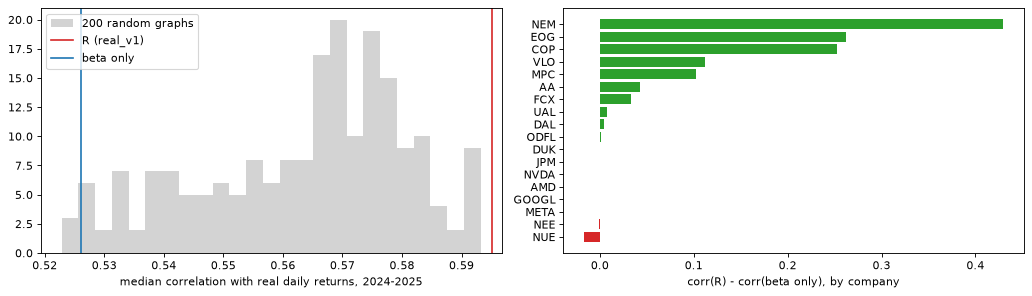

In [5]:
# Is the gain of R over beta-only more than day-to-day luck? Bootstrap over days (blocks of 5 days).
def median_corr_gain(index):
    y = real.iloc[index]
    gain = []
    for t in TICKERS:
        gain.append(np.corrcoef(y[t], ref_real[t].iloc[index])[0, 1] - np.corrcoef(y[t], beta_only[t].iloc[index])[0, 1])
    return np.median(gain), np.mean(gain)


rng = np.random.default_rng(11)
blocks = np.arange(0, len(real) - 4, 5)
draws = []
for _ in range(500):
    starts = rng.choice(blocks, len(blocks))
    draws.append(median_corr_gain(np.concatenate([np.arange(s, s + 5) for s in starts])))
draws = np.array(draws)
point = median_corr_gain(np.arange(len(real)))
print(f"median corr gain of R over beta only: {point[0]:.3f}, 95% CI [{np.quantile(draws[:, 0], 0.025):.3f}, "
      f"{np.quantile(draws[:, 0], 0.975):.3f}]")
print(f"mean corr gain: {point[1]:.3f}, 95% CI [{np.quantile(draws[:, 1], 0.025):.3f}, "
      f"{np.quantile(draws[:, 1], 0.975):.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(random_fits["median corr"], bins=25, color="lightgrey", label="200 random graphs")
for name, color in (("R (real_v1)", "C3"), ("beta only", "C0")):
    axes[0].axvline(summary_fit.loc[name, "median corr"], color=color, label=name)
axes[0].set_xlabel("median correlation with real daily returns, 2024-2025")
axes[0].legend()
gain = (fits["R (real_v1)"]["corr"] - fits["beta only"]["corr"]).sort_values()
axes[1].barh(gain.index, gain, color=np.where(gain > 0, "C2", "C3"))
axes[1].set_xlabel("corr(R) - corr(beta only), by company")
plt.tight_layout()
plt.show()

## 2. Simulation runs

Daily close of a run = last two-sided midpoint of the session; simulated daily return = its log change. The first
10 sessions (warmup) are dropped everywhere. Cells of E5: investor mix × herding, 30 seeds each (3001–3030). If the
full E5 is not there yet, the short one (seeds 3001–3010) is used, and without it the three 18-company pilot runs.

**Collapsed runs** are left out of the cells: a run where the daily close of some company fell below half of its
reference R (or rose above twice it) at least once after warmup. The rule only removes runs of the trend mix; their
number is printed below.

**Controls on seeds 3001–3010 of the main cell** (mixed investors, h = 0.2, all other settings as in E5). The row
`mixed, h=0.2, seeds 3001-3010` is the main cell on exactly those seeds:

- **random graphs**: the first two random graphs of the list above; the agents believe the random graph;
- **flat inputs**: `real_v1`, but every external series frozen at its level of 2 January 2024, so nothing happens
  outside the market. What remains in the returns is the market's own dynamics.

Only differences between the main cell and these controls, on the same seeds, say something about the graph or
about the inputs.


In [6]:
def sim_returns(run_dir):
    book = pd.read_parquet(run_dir / "book.parquet", columns=["t", "asset", "best_bid", "best_ask"])
    book = book.loc[(book.best_bid > 0) & (book.best_ask > 0)]
    book = book.assign(mid=(book.best_bid + book.best_ask) / 2, session=np.floor(book.t).astype(int))
    close = book.groupby(["session", "asset"]).mid.last().unstack().reindex(range(len(dates))).ffill()
    out = np.log(close).diff().iloc[1:]
    out.index, out.columns = real.index, TICKERS
    out.iloc[:WARMUP] = np.nan
    return out


def load_runs(directory, run_ids):
    # Simulated daily returns of several runs, cached next to the runs.
    cache = directory / "daily_returns.parquet"
    if cache.exists():
        table = pd.read_parquet(cache)
        if set(run_ids) <= set(table.run_id):
            return {r: g.drop(columns="run_id") for r, g in table.groupby("run_id") if r in set(run_ids)}
    out = {r: sim_returns(directory / r) for r in run_ids}
    pd.concat([frame.assign(run_id=r) for r, frame in out.items()]).to_parquet(cache)
    return out


def complete(directory, n):
    path = directory / "summary.csv"
    return path.exists() and len(pd.read_csv(path)) >= n


def worst_gaps(directory, run_ids):
    # Largest |ln(close / R)| of a run after warmup, R being the reference the run logged; cached next to the runs.
    cache = directory / "worst_gap.csv"
    known = pd.read_csv(cache).set_index("run_id").worst_gap if cache.exists() else pd.Series(dtype=float)
    missing = [r for r in run_ids if r not in known.index]
    for r in missing:
        book = pd.read_parquet(directory / r / "book.parquet", columns=["t", "asset", "best_bid", "best_ask"])
        book = book.loc[(book.best_bid > 0) & (book.best_ask > 0)]
        book = book.assign(mid=(book.best_bid + book.best_ask) / 2, session=np.floor(book.t).astype(int))
        val = pd.read_parquet(directory / r / "valuations.parquet", columns=["t", "asset", "reference"])
        val = val.assign(session=np.floor(val.t).astype(int))
        close = book.groupby(["session", "asset"]).mid.last().unstack()
        ref = val.groupby(["session", "asset"]).reference.last().unstack()
        known[r] = float(np.log(close / ref).loc[WARMUP:len(dates) - 1].abs().max().max())
    if missing:
        known.rename("worst_gap").rename_axis("run_id").to_csv(cache)
    return known




SEEDS = list(range(3001, 3011))   # the seeds of the controls
CELLS, DROPPED = {}, {}
SOURCE = next((d for d, n in (("e5", 270), ("e5_short", 90)) if complete(RESULTS / d, n)), None)
if SOURCE is not None:
    e5 = pd.read_csv(RESULTS / SOURCE / "summary.csv")
    loaded = load_runs(RESULTS / SOURCE, list(e5.run_id))
    # Collapsed: the close of some company fell below half of its reference R (or rose above twice it).
    gaps = worst_gaps(RESULTS / SOURCE, list(e5.run_id))
    for (mix, h), group in e5.groupby(["agents.composition", "agents.herding.h"]):
        kept = [r for r in group.run_id if gaps[r] <= np.log(2)]
        DROPPED[f"{mix}, h={h}"] = f"{len(group) - len(kept)} of {len(group)}"
        CELLS[f"{mix}, h={h}"] = [loaded[r] for r in kept]
    MAIN = "mixed, h=0.2"
    main = e5.loc[(e5["agents.composition"] == "mixed") & (e5["agents.herding.h"] == 0.2)]
    if len(main) > len(SEEDS):
        CELLS[f"{MAIN}, seeds 3001-3010"] = [loaded[r] for r in main.loc[main.seed.isin(SEEDS)].run_id]
else:
    pilot = pd.read_csv(RESULTS / "pilot" / "summary.csv")
    pilot = pilot.loc[pilot["price_log_change__JPM"].notna() & pilot["price_log_change__NVDA"].notna()]
    CELLS["pilot: mixed, h=0.2"] = list(load_runs(RESULTS / "pilot", list(pilot.run_id)).values())
    MAIN = "pilot: mixed, h=0.2"
print("simulation source:", SOURCE or "pilot")
print("collapsed runs left out:", DROPPED)

# Runs made before the target-position rule (flow sizing: "buy while the signal is positive"), kept for comparison.
BEFORE = {}
if (RESULTS / "e5_before_fixes" / "summary.csv").exists():
    old = pd.read_csv(RESULTS / "e5_before_fixes" / "summary.csv")
    old = old.loc[(old["agents.composition"] == "network") & (old["agents.herding.h"] == 0.0)]
    BEFORE["before the fix: network, h=0.0"] = list(load_runs(RESULTS / "e5_before_fixes", list(old.run_id)).values())

# Controls on seeds 3001-3010 of the main cell (mixed, h = 0.2): random graphs and flat external inputs.
base = load_config(ROOT / "configs" / "f6_e5.yaml").base


def control_runs(name, out_dir, **changes):
    if not (out_dir / "summary.csv").exists():   # 10 runs of ~10 minutes on 8 processes
        out_dir.mkdir(parents=True, exist_ok=True)
        spec = {"base": copy.deepcopy(asdict(base) | {"name": name, **changes}), "seeds": SEEDS, "grid": {}}
        path = out_dir.parent / f"{out_dir.name}.yaml"
        path.write_text(yaml.safe_dump(spec, sort_keys=False))
        run_experiment(path, out_dir, workers=8)
    summary = pd.read_csv(out_dir / "summary.csv")
    assert sorted(summary.seed) == SEEDS
    return list(load_runs(out_dir, list(summary.run_id)).values())


RANDOM_SIM = {}
for k in (0, 1):
    graph_dir = RESULTS / "random_graphs" / f"g{k + 1}"
    if not (graph_dir / "nodes.csv").exists():
        save_graph(RANDOM[k][0], graph_dir)
    RANDOM_SIM[f"random graph {k + 1}"] = control_runs(
        f"f6_random_graph_{k + 1}", RESULTS / "random_graph_same_seeds" / f"g{k + 1}", graph=str(graph_dir))

if not api.table_path(S.EXTERNAL, scenario="f6_flat_2024").exists():
    flat = pd.DataFrame({c: np.full(len(levels), float(levels[c].iloc[0])) for c in levels.columns},
                        index=pd.RangeIndex(len(levels), name="session"))
    flat.insert(0, "date", pd.Series(pd.NaT, index=flat.index, dtype="datetime64[ns]"))
    api.write_table(flat, S.EXTERNAL, scenario="f6_flat_2024")
FLAT_SIM = {"flat inputs": control_runs("f6_flat_inputs", RESULTS / "flat_inputs", external="f6_flat_2024")}
if SOURCE is not None:
    assert set(SEEDS) <= set(main.seed)
print({name: len(runs) for name, runs in (CELLS | RANDOM_SIM | FLAT_SIM).items()})

simulation source: e5
collapsed runs left out: {'mixed, h=0.0': '0 of 30', 'mixed, h=0.2': '0 of 30', 'mixed, h=0.4': '0 of 30', 'network, h=0.0': '0 of 30', 'network, h=0.2': '0 of 30', 'network, h=0.4': '0 of 30', 'trend, h=0.0': '0 of 30', 'trend, h=0.2': '4 of 30', 'trend, h=0.4': '2 of 30'}
{'mixed, h=0.0': 30, 'mixed, h=0.2': 30, 'mixed, h=0.4': 30, 'network, h=0.0': 30, 'network, h=0.2': 30, 'network, h=0.4': 30, 'trend, h=0.0': 30, 'trend, h=0.2': 26, 'trend, h=0.4': 28, 'mixed, h=0.2, seeds 3001-3010': 10, 'random graph 1': 10, 'random graph 2': 10, 'flat inputs': 10}


## 3. Event study: days with a large commodity move

Events: the 5% of days of 2024–2025 with the largest |Δ ln| of the commodity (after warmup), taken in order of size;
for a window of several days an event whose window would share a day with an already chosen event is skipped, so
windows never overlap. Every event is signed by the direction of the commodity, so a positive number means "moved
with the commodity".

- **Real**: mean signed return of every company over the events; 95% interval from a **bootstrap over blocks of
  10 trading days** (events in the same block are resampled together, because nearby events share market moods).
- **Simulation**: the same mean on the same days, averaged over the runs of the cell. Because our market may be
  slower, the two-day response (day of the event plus the next day) is shown too.
- **Abnormal** response: the return minus market beta × S&P 500 return of the day, in reality and in the model
  alike. On oil days the index moves too, and every model that knows the betas gets that part right for free.
  Subtracting the beta does not remove other joint moves of that day (sector news, rates), so the real mean is
  the reaction to the whole day, and a match is a **similarity of the reaction pattern**, not an isolated effect
  of oil.
- **Controls**: R and simulations on random graphs, and the flat-input runs (which see no oil move at all).


In [7]:
def events_of(column, share=0.05, days=1):
    # The largest |moves| in turn; a day whose window [day, day + days) overlaps a chosen window is skipped.
    move = real[column].iloc[WARMUP:-1]      # the last day has no "next day"
    position = dict(zip(real.index, range(len(real))))
    chosen, used = [], set()
    for day in move.abs().sort_values(ascending=False).index:
        window = set(range(position[day], position[day] + days))
        if window & used:
            continue
        chosen.append(day)
        used |= window
        if len(chosen) == round(share * len(move)):
            break
    return pd.Series(np.sign(move.loc[chosen]), index=chosen).sort_index()


def block_bootstrap(values, days_index, rng, draws=2000, block=10):
    # Means over resampled blocks of `block` trading days; rows of `values` belong to the days in `days_index`.
    blocks = real.index.get_indexer(days_index) // block
    groups = [np.flatnonzero(blocks == b) for b in np.unique(blocks)]
    out = np.empty((draws, values.shape[1]))
    for k in range(draws):
        pick = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        out[k] = values[pick].mean(axis=0)
    return out


def responses(frame, events, days=1, abnormal=False):
    # Events x companies: signed response over `days` days starting at the event.
    data = frame[TICKERS]
    if abnormal:
        data = data - np.outer(real["sp500"], BETA)
    position = real.index.get_indexer(events.index)
    total = sum(data.to_numpy()[position + d] for d in range(days))
    return total * events.to_numpy()[:, None]


def compare(model, truth, lo, hi):
    return {"corr across companies": np.corrcoef(model, truth)[0, 1],
            "inside real 95% CI": np.mean((model >= lo) & (model <= hi)),
            "same sign": np.mean(np.sign(model) == np.sign(truth)),
            "size ratio": float(model @ truth / (truth @ truth))}


def event_study(column, days=1, abnormal=False):
    events = events_of(column, days=days)
    truth_events = responses(real, events, days, abnormal)
    truth = truth_events.mean(axis=0)
    boot = block_bootstrap(truth_events, events.index, np.random.default_rng(3))
    lo, hi = np.quantile(boot, 0.025, axis=0), np.quantile(boot, 0.975, axis=0)
    means = {"R (real_v1)": responses(ref_real, events, days, abnormal).mean(axis=0),
             "beta only": responses(beta_only, events, days, abnormal).mean(axis=0)}
    for name, runs in (CELLS | RANDOM_SIM | FLAT_SIM).items():
        means["sim: " + name] = np.mean([responses(r, events, days, abnormal).mean(axis=0) for r in runs], axis=0)
    table = pd.DataFrame({name: compare(m, truth, lo, hi) for name, m in means.items()}).T
    control = pd.DataFrame([compare(responses(r, events, days, abnormal).mean(axis=0), truth, lo, hi)
                            for r in ref_random])
    table.loc["R of random graphs: mean"] = control.mean()
    table.loc["R of random graphs: 95th percentile"] = control.quantile(0.95)
    table.loc["share of random R >= R (real_v1)"] = (control >= table.loc["R (real_v1)"]).mean()
    detail = pd.DataFrame({"real": truth, "real lo": lo, "real hi": hi, **means}, index=TICKERS)
    return table, detail, events


oil_table, oil_detail, oil_events = event_study("wti", abnormal=True)
print(f"oil: {len(oil_events)} events, {int((oil_events > 0).sum())} up; mean |move| "
      f"{real.loc[oil_events.index, 'wti'].abs().mean():.3f}; S&P 500 moved with oil by "
      f"{(real.loc[oil_events.index, 'sp500'] * oil_events).mean():+.4f} on average")
oil_table.round(3)

oil: 24 events, 10 up; mean |move| 0.050; S&P 500 moved with oil by +0.0088 on average


,corr across companies,inside real 95% CI,same sign,size ratio
R (real_v1),0.874,0.722,0.889,0.764
beta only,NaN,0.444,0.000,0.000
"sim: mixed, h=0.0",0.834,0.722,0.556,0.971
"sim: mixed, h=0.2",0.833,0.722,0.611,0.972
"sim: mixed, h=0.4",0.818,0.778,0.611,0.904
"sim: network, h=0.0",0.829,0.778,0.611,0.966
"sim: network, h=0.2",0.832,0.722,0.611,0.982
"sim: network, h=0.4",0.797,0.722,0.611,0.884
"sim: trend, h=0.0",0.795,0.611,0.611,0.912
"sim: trend, h=0.2",0.784,0.500,0.722,0.903


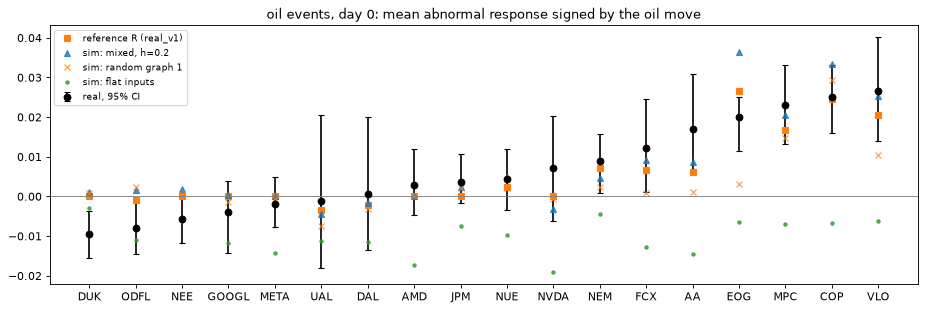

In [8]:
def plot_events(detail, title, extra=()):
    order = detail["real"].sort_values().index
    x = np.arange(len(order))
    _, ax = plt.subplots(figsize=(14, 4.2))
    ax.errorbar(x, detail.loc[order, "real"], yerr=[detail.loc[order, "real"] - detail.loc[order, "real lo"],
                detail.loc[order, "real hi"] - detail.loc[order, "real"]], fmt="ko", capsize=3, label="real, 95% CI")
    ax.plot(x, detail.loc[order, "R (real_v1)"], "s", color="C1", label="reference R (real_v1)")
    for name, marker in ((f"sim: {MAIN}", "^"), *extra):
        ax.plot(x, detail.loc[order, name], marker, label=name, alpha=0.8)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(x, order)
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.show()


plot_events(oil_detail, "oil events, day 0: mean abnormal response signed by the oil move",
            extra=(("sim: random graph 1", "x"), ("sim: flat inputs", ".")))

The same comparison for the two-day response, for the raw (not abnormal) response and for copper.

In [9]:
variants = {
    "oil, day 0, abnormal": oil_table,
    "oil, days 0-1, abnormal": event_study("wti", days=2, abnormal=True)[0],
    "oil, day 0, raw": event_study("wti", days=1, abnormal=False)[0],
    "copper, day 0, abnormal": event_study("copper", days=1, abnormal=True)[0],
    "copper, days 0-1, abnormal": event_study("copper", days=2, abnormal=True)[0],
}
for metric in ("corr across companies", "size ratio", "inside real 95% CI", "same sign"):
    print(metric)
    display(pd.DataFrame({name: table[metric] for name, table in variants.items()}).round(3))

corr across companies


,"oil, day 0, abnormal","oil, days 0-1, abnormal","oil, day 0, raw","copper, day 0, abnormal","copper, days 0-1, abnormal"
R (real_v1),0.874,0.836,0.888,0.829,0.789
beta only,NaN,NaN,0.214,NaN,NaN
"sim: mixed, h=0.0",0.834,0.805,0.814,0.822,0.763
"sim: mixed, h=0.2",0.833,0.799,0.812,0.812,0.755
"sim: mixed, h=0.4",0.818,0.791,0.799,0.787,0.741
"sim: network, h=0.0",0.829,0.804,0.807,0.825,0.747
"sim: network, h=0.2",0.832,0.783,0.809,0.816,0.739
"sim: network, h=0.4",0.797,0.783,0.771,0.795,0.733
"sim: trend, h=0.0",0.795,0.753,0.757,0.766,0.708
"sim: trend, h=0.2",0.784,0.721,0.739,0.751,0.694


size ratio


,"oil, day 0, abnormal","oil, days 0-1, abnormal","oil, day 0, raw","copper, day 0, abnormal","copper, days 0-1, abnormal"
R (real_v1),0.764,0.955,0.857,1.239,0.868
beta only,0.000,0.000,0.443,0.000,0.000
"sim: mixed, h=0.0",0.971,1.188,0.979,1.492,1.095
"sim: mixed, h=0.2",0.972,1.177,0.978,1.476,1.075
"sim: mixed, h=0.4",0.904,1.195,0.928,1.378,1.057
"sim: network, h=0.0",0.966,1.192,0.970,1.510,1.060
"sim: network, h=0.2",0.982,1.202,0.979,1.495,1.058
"sim: network, h=0.4",0.884,1.216,0.906,1.385,1.042
"sim: trend, h=0.0",0.912,1.282,0.901,1.452,1.173
"sim: trend, h=0.2",0.903,1.295,0.885,1.393,1.150


inside real 95% CI


,"oil, day 0, abnormal","oil, days 0-1, abnormal","oil, day 0, raw","copper, day 0, abnormal","copper, days 0-1, abnormal"
R (real_v1),0.722,0.833,0.944,0.833,0.944
beta only,0.444,0.611,0.722,0.722,0.833
"sim: mixed, h=0.0",0.722,0.722,0.944,0.722,0.722
"sim: mixed, h=0.2",0.722,0.722,0.944,0.722,0.722
"sim: mixed, h=0.4",0.778,0.722,0.944,0.722,0.722
"sim: network, h=0.0",0.778,0.722,0.944,0.722,0.722
"sim: network, h=0.2",0.722,0.722,0.889,0.667,0.722
"sim: network, h=0.4",0.722,0.722,0.944,0.611,0.722
"sim: trend, h=0.0",0.611,0.667,0.944,0.611,0.444
"sim: trend, h=0.2",0.500,0.667,0.944,0.556,0.389


same sign


,"oil, day 0, abnormal","oil, days 0-1, abnormal","oil, day 0, raw","copper, day 0, abnormal","copper, days 0-1, abnormal"
R (real_v1),0.889,0.889,0.944,0.778,0.556
beta only,0.000,0.000,0.944,0.000,0.000
"sim: mixed, h=0.0",0.556,0.667,0.944,0.722,0.444
"sim: mixed, h=0.2",0.611,0.667,0.944,0.722,0.444
"sim: mixed, h=0.4",0.611,0.667,0.944,0.667,0.444
"sim: network, h=0.0",0.611,0.667,0.944,0.667,0.444
"sim: network, h=0.2",0.611,0.667,0.944,0.722,0.444
"sim: network, h=0.4",0.611,0.667,0.944,0.667,0.444
"sim: trend, h=0.0",0.611,0.667,0.944,0.722,0.389
"sim: trend, h=0.2",0.722,0.667,0.944,0.722,0.389


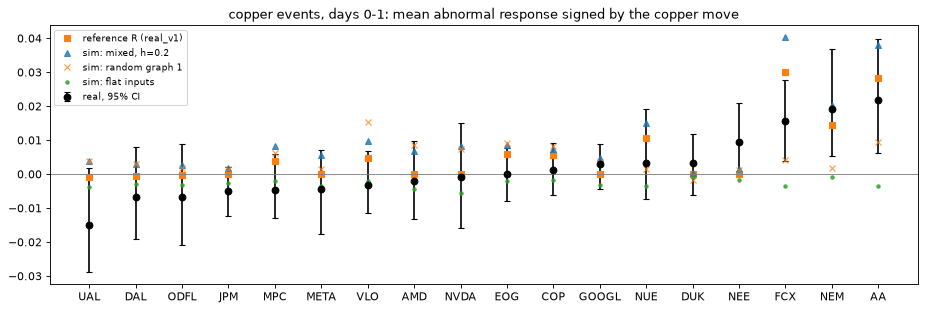

In [10]:
copper_table, copper_detail, copper_events = event_study("copper", days=2, abnormal=True)
plot_events(copper_detail, "copper events, days 0-1: mean abnormal response signed by the copper move",
            extra=(("sim: random graph 1", "x"), ("sim: flat inputs", ".")))

### Weeks with an oil move above 5% (the F8 formulation)

Non-overlapping calendar weeks; the response is the weekly return signed by the oil move, abnormal to the index.
Over a week the slowness of our market matters less.

In [11]:
def weekly(frame):
    out = frame.copy()
    out.iloc[:WARMUP] = np.nan
    return out.groupby(pd.Grouper(freq="W-FRI")).sum(min_count=4)


week_real = weekly(real)
week_oil = week_real["wti"].dropna()
week_events = week_oil[week_oil.abs() > 0.05]
week_sign = np.sign(week_events)


def week_response(frame):
    w = weekly(frame)[TICKERS] - np.outer(week_real["sp500"], BETA)
    return w.loc[week_events.index].to_numpy() * week_sign.to_numpy()[:, None]


truth_weeks = week_response(real)
truth = truth_weeks.mean(axis=0)
rng = np.random.default_rng(5)
boot = truth_weeks[rng.integers(0, len(week_events), (2000, len(week_events)))].mean(axis=1)
lo, hi = np.quantile(boot, 0.025, axis=0), np.quantile(boot, 0.975, axis=0)
rows = {"R (real_v1)": compare(week_response(ref_real).mean(axis=0), truth, lo, hi)}
for name, runs in (CELLS | RANDOM_SIM | FLAT_SIM).items():
    rows["sim: " + name] = compare(np.mean([week_response(r).mean(axis=0) for r in runs], axis=0), truth, lo, hi)
control = pd.DataFrame([compare(week_response(r).mean(axis=0), truth, lo, hi) for r in ref_random])
week_table = pd.DataFrame(rows).T
week_table.loc["R of random graphs: mean"] = control.mean()
week_table.loc["R of random graphs: 95th percentile"] = control.quantile(0.95)
week_table.loc["share of random R >= R (real_v1)"] = (control >= week_table.loc["R (real_v1)"]).mean()
print(f"{len(week_events)} weeks with |oil move| > 5%, {int((week_sign > 0).sum())} up")
week_table.round(3)

18 weeks with |oil move| > 5%, 8 up


,corr across companies,inside real 95% CI,same sign,size ratio
R (real_v1),0.899,0.944,0.889,0.703
"sim: mixed, h=0.0",0.888,0.833,0.667,0.951
"sim: mixed, h=0.2",0.891,0.833,0.667,0.938
"sim: mixed, h=0.4",0.890,0.833,0.556,0.948
"sim: network, h=0.0",0.890,0.833,0.667,0.960
"sim: network, h=0.2",0.885,0.833,0.556,0.950
"sim: network, h=0.4",0.895,0.833,0.611,0.945
"sim: trend, h=0.0",0.887,0.667,0.500,1.180
"sim: trend, h=0.2",0.877,0.667,0.500,1.174
"sim: trend, h=0.4",0.887,0.667,0.611,1.155


### Stylized facts of daily returns, with controls

Median over the 18 companies (after warmup), mean over the runs of a row (30 for the main cell, 10 for the
others). These numbers were **targets of the
calibration** (the real autocorrelation of −0.05 was matched on purpose), so the real-graph row agreeing with
reality is expected; the question here is whether the agreement needs the graph and the real inputs. The random
graphs and the flat inputs run on the same seeds as the main cell.


In [12]:
def facts(frame):
    x = frame[TICKERS].iloc[WARMUP:]
    return {"autocorr r, lag 1": x.apply(lambda c: c.autocorr(1)).median(),
            "autocorr |r|, lag 1": x.abs().apply(lambda c: c.autocorr(1)).median(),
            "excess kurtosis": x.kurt().median(),
            "daily std, %": 100 * x.std().median(),
            "corr with real returns": x.corrwith(real[TICKERS].iloc[WARMUP:]).median()}


rows = {"real 2024-2025": facts(real), "R (real_v1)": facts(ref_real)}
same = {k: v for k, v in CELLS.items() if k.startswith(f"{MAIN}, seeds")}
for name, runs in ({MAIN: CELLS[MAIN]} | same | RANDOM_SIM | FLAT_SIM).items():
    rows["sim: " + name] = pd.DataFrame([facts(r) for r in runs]).mean()
facts_table = pd.DataFrame(rows).T
facts_table.round(3)

,"autocorr r, lag 1","autocorr |r|, lag 1",excess kurtosis,"daily std, %",corr with real returns
real 2024-2025,-0.035,0.097,6.887,2.270,1.000
R (real_v1),-0.060,0.228,15.631,1.292,0.595
"sim: mixed, h=0.2",-0.046,0.163,5.393,1.799,0.462
"sim: mixed, h=0.2, seeds 3001-3010",-0.044,0.168,5.125,1.791,0.450
sim: random graph 1,-0.067,0.170,5.366,1.696,0.421
sim: random graph 2,-0.063,0.169,5.467,1.703,0.423
sim: flat inputs,-0.545,0.330,0.945,0.728,-0.003


## 4. Lag: does yesterday's parent predict today's child?

For every edge of `real_v1` that does not start at the index (33 edges): OLS of the child's return on the parent's
return of the previous day. In the simulation the parent of a commodity edge is the real commodity, the parent of
a company edge is the simulated price of that company; one regression per run and edge.

Second, a pooled view that does not depend on single edges: every company's return on today's and yesterday's
change of its own reference path R (`b0`, `b1`). A market that prices the graph within the day has `b1 ≈ 0`.

The two answer different questions. The share of significant edges asks whether *some single edge* lags (with
the ordinary OLS t of each regression). The pooled `b1` asks whether *on average* the move implied by the graph
arrives a day late. Its observations (company × day) are not independent: companies move together on the same
day, and days follow each other. So its standard error is **clustered by blocks of 5 trading days** (all companies
of the block together), and the 95% interval below uses it; an ordinary t-statistic would overstate the
precision.

**Control:** the same lag regression for the 33 pairs of a random graph (pairs that are *not* edges of `real_v1`),
and for the simulations run on a random graph.

In [13]:
def ols_t(y, x):
    # OLS with an intercept; returns the coefficients of x and their t-statistics.
    mask = ~(np.isnan(y) | np.isnan(x).any(axis=1))
    y, x = y[mask], np.column_stack([np.ones(mask.sum()), x[mask]])
    beta, *_ = np.linalg.lstsq(x, y, rcond=None)
    resid = y - x @ beta
    cov = resid @ resid / (len(y) - x.shape[1]) * np.linalg.inv(x.T @ x)
    return beta[1:], beta[1:] / np.sqrt(np.diag(cov)[1:])


def lag_tests(frame, pairs):
    # frame: company returns to test; parents that are external come from the real data.
    rows = []
    for parent, child in pairs:
        source = frame[parent] if parent in TICKERS else real[parent]
        b, t = ols_t(frame[child].to_numpy(), source.shift(1).to_numpy()[:, None])
        rows.append({"edge": f"{parent}->{child}", "b_lag": b[0], "t_lag": t[0]})
    return pd.DataFrame(rows).set_index("edge")


def ols_cluster(y, x, groups):
    # OLS with an intercept; standard errors clustered by `groups` (sandwich estimator, small-sample factor).
    mask = ~(np.isnan(y) | np.isnan(x).any(axis=1))
    y, x, groups = y[mask], np.column_stack([np.ones(mask.sum()), x[mask]]), groups[mask]
    beta, *_ = np.linalg.lstsq(x, y, rcond=None)
    resid = y - x @ beta
    bread = np.linalg.inv(x.T @ x)
    meat = np.zeros((x.shape[1], x.shape[1]))
    labels = np.unique(groups)
    for g in labels:
        score = x[groups == g].T @ resid[groups == g]
        meat += np.outer(score, score)
    n, k, m = len(y), x.shape[1], len(labels)
    cov = bread @ meat @ bread * (m / (m - 1)) * ((n - 1) / (n - k))
    return beta[1:], np.sqrt(np.diag(cov)[1:])


def own_reference(frame, reference):
    y = frame[TICKERS].to_numpy().ravel(order="F")
    x0 = reference[TICKERS].to_numpy().ravel(order="F")
    x1 = reference[TICKERS].shift(1).to_numpy().ravel(order="F")
    blocks = np.tile(np.arange(len(frame)) // 5, len(TICKERS))
    b, se = ols_cluster(y, np.column_stack([x0, x1]), blocks)
    return {"b0 (same day)": b[0], "b1 (next day)": b[1], "b1 clustered se": se[1],
            "b1 95% lo": b[1] - 1.96 * se[1], "b1 95% hi": b[1] + 1.96 * se[1]}


real_after = real.copy()
real_after.iloc[:WARMUP] = np.nan
PLACEBO = [pair for pair in RANDOM[0][1] if pair not in REAL_PAIRS]


def lag_summary(runs, reference, pairs=REAL_PAIRS):
    tests = [lag_tests(r, pairs) for r in runs]
    t = pd.concat([x.t_lag for x in tests], axis=1, keys=range(len(tests)))
    values = t.to_numpy().ravel()
    own = pd.DataFrame([own_reference(r, reference) for r in runs]).mean()
    return {"median t": np.nanmedian(values), "share |t| > 2": np.mean(np.abs(values) > 2),
            "share t > 2": np.mean(values > 2), **own}, t.mean(axis=1)


lag_rows, lag_by_edge = {}, {}
lag_rows["real"], lag_by_edge["real"] = lag_summary([real_after], ref_real)
for name, runs in CELLS.items():
    lag_rows["sim: " + name], lag_by_edge["sim: " + name] = lag_summary(runs, ref_real)
for name, runs in FLAT_SIM.items():
    lag_rows["sim: " + name], _ = lag_summary(runs, ref_real)
for k, (name, runs) in enumerate(RANDOM_SIM.items()):
    lag_rows[f"sim: {name}, its own edges"], _ = lag_summary(runs, ref_random[k], RANDOM[k][1])
for name, runs in BEFORE.items():
    lag_rows["sim " + name], _ = lag_summary(runs, ref_real)
lag_rows["real, placebo pairs"], _ = lag_summary([real_after], ref_real, PLACEBO)
lag_rows[f"sim: {MAIN}, placebo pairs"], _ = lag_summary(CELLS[MAIN], ref_real, PLACEBO)
lag_table = pd.DataFrame(lag_rows).T
lag_table.round(3)

,median t,share |t| > 2,share t > 2,b0 (same day),b1 (next day),b1 clustered se,b1 95% lo,b1 95% hi
real,-0.358,0.000,0.000,0.993,-0.068,0.033,-0.133,-0.003
"sim: mixed, h=0.0",2.289,0.528,0.524,1.037,0.191,0.019,0.154,0.228
"sim: mixed, h=0.2",2.145,0.534,0.520,1.040,0.184,0.020,0.144,0.223
"sim: mixed, h=0.4",2.616,0.598,0.587,0.964,0.244,0.022,0.202,0.287
"sim: network, h=0.0",3.145,0.592,0.583,1.033,0.196,0.021,0.156,0.237
"sim: network, h=0.2",2.843,0.580,0.566,1.033,0.197,0.021,0.155,0.238
"sim: network, h=0.4",3.346,0.631,0.614,0.955,0.258,0.025,0.209,0.307
"sim: trend, h=0.0",3.865,0.707,0.706,0.931,0.376,0.030,0.317,0.436
"sim: trend, h=0.2",3.938,0.719,0.716,0.916,0.394,0.034,0.327,0.461
"sim: trend, h=0.4",3.833,0.703,0.701,0.829,0.434,0.042,0.351,0.517


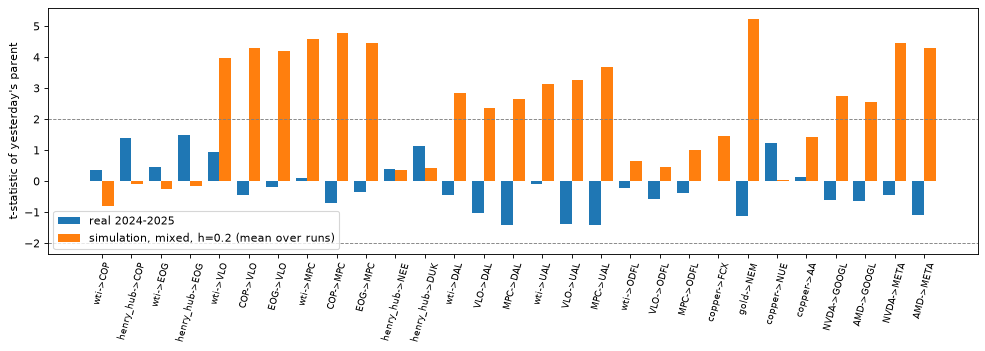

,weight,real t,"sim t (mixed, h=0.2)"
wti->COP,0.51,0.36,-0.79
henry_hub->COP,0.01,1.38,-0.10
wti->EOG,0.55,0.45,-0.24
henry_hub->EOG,0.00,1.48,-0.15
wti->VLO,0.05,0.93,3.96
COP->VLO,0.54,-0.44,4.29
EOG->VLO,0.18,-0.21,4.20
wti->MPC,0.02,0.09,4.58
COP->MPC,0.48,-0.71,4.78
EOG->MPC,0.14,-0.36,4.47


In [14]:
edges = pd.DataFrame({"weight": {f"{e.parent}->{e.child}": e.w_full for e in GRAPH.edges if e.parent != "sp500"},
                      "real t": lag_by_edge["real"], f"sim t ({MAIN})": lag_by_edge[f"sim: {MAIN}"]})
fig, ax = plt.subplots(figsize=(15, 4))
x = np.arange(len(edges))
ax.bar(x - 0.2, edges["real t"], 0.4, label="real 2024-2025")
ax.bar(x + 0.2, edges[f"sim t ({MAIN})"], 0.4, label=f"simulation, {MAIN} (mean over runs)")
for level in (-2, 2):
    ax.axhline(level, color="grey", lw=0.8, ls="--")
ax.set_xticks(x, edges.index, rotation=75, fontsize=8)
ax.set_ylabel("t-statistic of yesterday's parent")
ax.legend()
plt.show()
edges.round(2)

## 5. How close are the simulated returns to the real ones day by day?

Correlation of the simulated daily return of a company with its real return (median over companies, mean over
runs), next to the same number for the reference R. Company news is missing from the simulation, so this can not
be high; the question is only whether the real graph does better than a random one. Two-day returns are added
because the simulated market spreads a move over two days.

In [15]:
def daily_fit(frames, window=1):
    values = []
    for frame in frames:
        a = real_after[TICKERS].rolling(window).sum().iloc[window - 1::window]
        b = frame[TICKERS].rolling(window).sum().iloc[window - 1::window]
        values.append(a.corrwith(b).median())
    return float(np.mean(values))


rows = {"R (real_v1)": [ref_real], "beta only": [beta_only]}
rows |= {"sim: " + name: runs for name, runs in (CELLS | RANDOM_SIM | FLAT_SIM | BEFORE).items()}
closeness = pd.DataFrame({name: {"1-day returns": daily_fit(frames, 1), "2-day returns": daily_fit(frames, 2),
                                 "5-day returns": daily_fit(frames, 5)} for name, frames in rows.items()}).T
control = pd.DataFrame([{"1-day returns": daily_fit([r], 1), "2-day returns": daily_fit([r], 2),
                         "5-day returns": daily_fit([r], 5)} for r in ref_random])
closeness.loc["R of random graphs: mean"] = control.mean()
closeness.loc["R of random graphs: 95th percentile"] = control.quantile(0.95)
closeness.round(3)

,1-day returns,2-day returns,5-day returns
R (real_v1),0.595,0.583,0.640
beta only,0.528,0.520,0.499
"sim: mixed, h=0.0",0.475,0.479,0.586
"sim: mixed, h=0.2",0.462,0.474,0.583
"sim: mixed, h=0.4",0.406,0.429,0.563
"sim: network, h=0.0",0.472,0.474,0.587
"sim: network, h=0.2",0.451,0.465,0.580
"sim: network, h=0.4",0.397,0.417,0.547
"sim: trend, h=0.0",0.371,0.371,0.480
"sim: trend, h=0.2",0.347,0.350,0.456


## 6. What these checks say

Numbers from the full E5 (9 cells × 30 seeds, 270 runs; the 6 collapsed runs of the trend mix at h ≥ 0.2 are left
out) and three controls on seeds 3001–3010 of the main cell (mixed, h = 0.2): two random graphs and flat external
inputs. On exactly those 10 seeds the main cell gives the same numbers as on all 30 (rows `seeds 3001-3010`).

**Calibration or check.** Only section 1 is out of sample: the graph weights and betas come from 2021–2023. The
simulation parameters were chosen on the same 502 sessions of 2024–2025, so the market-level numbers below are
calibration results. What they can show is a difference between `real_v1` and the controls on the same seeds.

**The graph, out of sample.** R of `real_v1` correlates with real daily returns at 0.595 (median over companies),
beta-only at 0.526, random graphs with the same degrees at 0.563 on average; none of 200 random graphs reaches
`real_v1` on this median. The gain sits in the oil chain (0.60 against 0.42 for beta-only; 4.5% of random graphs
are at least as good) and in metals and mining (0.59 against 0.53; 0%); for airlines and trucking 62% of random
graphs do as well, and for the seven companies whose only real edge is the index the graph *is* beta-only. Mean
gain in correlation over beta-only, per company: 0.068, 95% CI [0.042, 0.108] (bootstrap over 5-day blocks); the
median of the per-company gains is only 0.003 [0.000, 0.011], because most companies gain nothing.

**Event study: similarity of the reaction pattern.** On the 24 largest oil days (non-overlapping windows,
bootstrap over 10-day blocks) the mean abnormal reaction of the 18 companies in the main cell correlates with the
real one at 0.83 and has a size ratio of 0.97 (0.84 and 0.98 on seeds 3001–3010); R gives 0.87 and 0.76. On the same seeds the random graphs give
0.68 and 0.53 with size 0.47 and 0.50, and flat inputs 0.14. Subtracting the beta does not remove other joint
moves of those days, so this is a similarity of reaction patterns on oil days, not an isolated effect of oil or a
proof of particular transmission paths. For the one-day oil correlation R of `real_v1` is not unusual (15.5% of
random graphs reach it); for the two-day window, copper events and weeks with an oil move above 5% few or no
random graphs do (0.5%, 0%, 3%).
*Metrics that prove nothing here:* the share of companies with the right sign and the share inside the real
confidence interval (random graphs reach them in 30–67% and 1–64% of cases).

**Stylized facts (calibration targets).** Lag-1 return autocorrelation: real −0.035, main cell −0.046, random
graphs −0.063 and −0.067, flat inputs −0.55. Lag-1 autocorrelation of |r|: real 0.10, main cell 0.16, random
graphs 0.17, flat inputs 0.33. Excess kurtosis: real 6.9, main cell 5.4 (5.1 on seeds 3001–3010), random graphs
5.4–5.5, flat inputs 0.9.
So the fat tails come from the real inputs, not from the agents; volatility clustering and the near-zero
autocorrelation do not depend on the graph, and the latter was tuned.

**Lag: two different questions.** Single edges: in reality no edge has a significant lag (0 of 29, ordinary OLS t
per edge regression), against 53–59% in the mixed and network cells at h ≤ 0.2, 60–63% at h = 0.4 and 70–72% in
the trend cells. Pooled next-day
coefficient `b1` (company return on yesterday's change of its own R, errors clustered by 5-day blocks): real
−0.068, 95% CI [−0.133, −0.003], a small reversal; main cell 0.184 [0.144, 0.223]; random graphs 0.19–0.22;
flat inputs 0. **Our agents are slower than the real market**: about a fifth of a move arrives a day late. The
lag test says nothing about the graph: simulations on random graphs show the same next-day coefficient.

**Day-by-day closeness** does not separate graphs either: 0.46 for `real_v1` (0.45 on seeds 3001–3010) and 0.42
for random graphs on the same seeds; over five days 0.58 against 0.50–0.52.

**Bottom line.** Survive the controls: the out-of-sample fit of R (concentrated in the oil chain and metals), and
the cross-company pattern and size of event reactions over two days, a week, and for copper. The match of daily
return statistics is a calibration result. Still to compute before F8: the stylized facts and the event study for
more random graphs, and the event study with placebo days.
